# Problem 3 - Problem statement 4: Đánh giá Giá trị Vòng đời Khách hàng (Customer Lifetime Value - CLV)



### 🎯 CÂU HỎI KINH DOANH — STATEMENT 4: CUSTOMER LIFETIME VALUE (CLV)

Để định hình chân dung khách hàng mục tiêu và xây dựng các chương trình CRM hiệu quả, bộ phận Marketing cần làm rõ **6 câu hỏi cốt lõi** sau đây:

*   **📊 Câu hỏi 1: Chân dung Hành vi Khách hàng Thô**
    *   *Mỗi khách hàng đã đóng góp bao nhiêu doanh thu, mua bao nhiêu lần và khoảng cách trung bình giữa các lần mua (Inter-purchase Days) là bao lâu?*

*   **⚖️ Câu hỏi 2: Cấu trúc Doanh thu & Quy luật Pareto 80/20**
    *   *Các nhóm khách hàng (VIP, High-value, Potential, Low-value) chiếm bao nhiêu % quy mô số lượng khách và đóng góp bao nhiêu % tổng doanh thu? Liệu quy luật Pareto có tồn tại rõ nét trong hệ thống không?*

*   **🔄 Câu hỏi 3: Sự Khác biệt Hành vi Giữa các Phân khúc**
    *   *Tỷ lệ khách hàng quay lại (Repeat Customer Rate), tần suất mua trung bình và giá trị đơn hàng trung bình (AOV) có sự chênh lệch như thế nào giữa các nhóm CLV?*

*   **⚠️ Câu hỏi 4: Nhận diện Rủi ro Rời bỏ (Churn Risk)**
    *   *Phân khúc nào có chu kỳ mua lại trung bình dài nhất? Nhóm nào cần được cảnh báo sớm về nguy cơ rời bỏ hệ thống?*

*   **🚀 Câu hỏi 5: Định hướng Ưu tiên Nguồn lực CRM**
    *   *Doanh nghiệp nên ưu tiên tập trung giữ chân nhóm khách hàng nào để bảo toàn nguồn doanh thu cốt lõi, và nên đầu tư ngân sách Marketing vào nhóm nào để tối ưu hóa tăng trưởng?*

*   **💰 Câu hỏi 6: Tối ưu hóa Chi phí Tiếp thị & Chăm sóc**
    *   *Đối với hai nhóm Potential và Low-value, thời điểm nào và hình thức can thiệp nào (tiếp thị cá nhân hóa sâu hay chiến dịch đại trà rộng rãi) là tối ưu nhất về mặt chi phí?*

### 📌  MEASURES - METRICS - KPIS (STATEMENT 4)

Để đảm bảo tính nhất quán và chuẩn hóa trong báo cáo, dưới đây là sơ đồ chi tiết ánh xạ từ dữ liệu thô (Measures) qua công thức tính toán (Metrics) cho đến chỉ số hiệu năng cốt lõi (KPIs) được áp dụng thực tế trong mã nguồn:

| Phân loại | Tên Chỉ số | Cột dữ liệu / Công thức trong Code | Ý nghĩa nghiệp vụ |
| :--- | :--- | :--- | :--- |
| **Thước đo (Measures)** | Số lượng | `quantity` (Bảng `order_details`) | Số lượng sản phẩm thô được ghi nhận trên mỗi dòng đơn hàng. |
| | Đơn giá | `unit_price` (Bảng `order_details`) | Giá niêm yết của một sản phẩm trước giảm giá. |
| | Giảm giá | `discount_amount` (Bảng `order_details`) | Giá trị khuyến mãi được trừ trực tiếp. |
| | Ngày đặt hàng | `order_date` (Bảng `orders_df`) | Mốc thời gian thực hiện giao dịch, định dạng thành công `datetime64`. |
| | Trạng thái | `order_status` (Bảng `orders_df`) | Trạng thái đơn hàng, lọc `'delivered'` để đảm bảo tính chính xác cho doanh thu thực nhận. |
| **Độ đo (Metrics)** | Doanh thu dòng hàng | `Revenue = (quantity * unit_price) - discount_amount` | Giá trị ròng thực tế thu về của từng sản phẩm sau khi trừ chiết khấu. |
| | Giá trị đơn hàng | `order_value` (Bảng `order_summary`) | Tổng số tiền khách hàng chi trả cho toàn bộ đơn hàng đó. |
| | Tổng doanh thu khách hàng (CLV) | `CustomerRevenue` (Bảng `customer_analysis`) | Tổng giá trị tài chính mà một khách hàng đóng góp cho doanh nghiệp trong toàn bộ thời gian quan sát. |
| | Tần suất mua hàng | `PurchaseFrequency` (Bảng `customer_analysis`) | Tổng số đơn hàng thành công của một khách hàng (`nunique` của `order_id`). |
| | Khoảng cách mua hàng | `InterPurchaseDays` (Bảng `customer_analysis`) | Số ngày trung bình giữa hai lần mua liên tiếp: `lifespan_days / (PurchaseFrequency - 1)`. **Chỉ xác định với khách Repeat; khách One-time = `NaN` (không phải 0).** |
| **KPIs theo Phân khúc** | % Tỷ trọng quy mô khách | `CustomerShare_%` | Tỷ lệ số lượng khách hàng của phân khúc chiếm bao nhiêu % trên tổng số khách. |
| | % Tỷ trọng doanh thu | `RevenueContribution_%` | Tỷ lệ doanh thu phân khúc đóng góp trên tổng doanh thu (Dùng kiểm chứng quy luật Pareto 80/20). |
| | Giá trị vòng đời trung bình | `AverageCLV` | Sức mua và giá trị tài chính trung bình của một khách hàng thuộc phân khúc đó mang lại. |
| | Tỷ lệ giữ chân phân khúc | `RepeatCustomerRate` | Tỷ lệ % khách hàng mua từ 2 lần trở lên trong nhóm, đo lường độ trung thành của phân khúc. |
| | Giá trị đơn hàng trung bình của phân khúc | `AverageAOV` | **Σ doanh thu phân khúc / Σ số đơn phân khúc** (trọng số theo đơn, cùng cách tính với AOV của PS3). |
| | Quy mô giỏ hàng trung bình của phân khúc | `AverageBasketSize` | **Σ số lượng sản phẩm / Σ số đơn** của phân khúc (cùng cách tính với Basket Size của PS3). |
| | Chu kỳ mua lại trung bình | `AverageInterPurchaseDays` | Chu kỳ mua lại trung bình **chỉ tính trên khách Repeat** của nhóm (bỏ qua One-time), dùng làm tín hiệu cảnh báo sớm Churn Risk. |

**Ghi chú phạm vi & định nghĩa (để đối chiếu với PS1, PS2, PS3):**
- Phạm vi: chỉ các đơn `delivered`; đơn vị tiền tệ: **VNĐ** (thống nhất với PS3).
- Tập khách hàng phân tích = khách có **ít nhất 1 đơn delivered** (không phải toàn bộ bảng `customers`); mẫu số của `CustomerShare_%` cũng là tập này.
- `Repeat Customer` = `PurchaseFrequency > 1` (giống PS2). Khác với "High Frequency" của PS1 (≥ trung vị).
- Phân khúc PS4 chia theo **phân vị doanh thu** (P95 / P80 / P50) nên **không so sánh trực tiếp** với 4 nhóm trung vị (Revenue × Frequency) của PS1.
- Các giá trị trung bình theo phân khúc (AOV, Basket Size) tính **theo tổng/đơn**, không phải trung bình của trung bình từng khách.

# 1 — Đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: '%.2f' % x)

customers_df = pd.read_csv('/content/customers_silver.csv', low_memory=False)
orders_df = pd.read_csv('/content/orders.csv', low_memory=False)
order_details = pd.read_csv('/content/Order_items.csv', low_memory=False)

# Làm sạch tên cột
for df in [customers_df, orders_df, order_details]:
    df.columns = df.columns.str.replace('^\ufeff', '', regex=True).str.strip()

# 2 — Kiểm tra Shape

In [2]:
print("Customers shape:", customers_df.shape)
print("Orders shape:", orders_df.shape)
print("Order details shape:", order_details.shape)

Customers shape: (121930, 6)
Orders shape: (646945, 9)
Order details shape: (714653, 7)


# 3 — Kiểm tra Columns

In [3]:
print("Customers columns:", customers_df.columns.tolist())
print("Orders columns:", orders_df.columns.tolist())
print("Order details columns:", order_details.columns.tolist())

Customers columns: ['customer_id', 'zip', 'signup_date', 'gender', 'age_group', 'acquisition_channel']
Orders columns: ['order_id', 'customer_id', 'sales_employee_id', 'order_date', 'order_source', 'order_status', 'device_type', 'comment', 'zip']
Order details columns: ['order_id', 'product_id', 'promo_id', 'promo_id_2', 'quantity', 'unit_price', 'discount_amount']


# 4 — Kiểm tra Datatype & Chuẩn hóa

In [4]:
orders_df["order_date"] = pd.to_datetime(orders_df["order_date"], errors="coerce")

for col in ["unit_price", "discount_amount"]:
    if order_details[col].dtype == 'object':
        order_details[col] = order_details[col].str.replace(',', '.')
    order_details[col] = pd.to_numeric(order_details[col], errors="coerce")
    n_bad = int(order_details[col].isna().sum())
    print(f"[{col}] số giá trị không chuyển được sang số (sẽ thay bằng 0): {n_bad}")
    order_details[col] = order_details[col].fillna(0.0)

print("Số order_date không đọc được:", int(orders_df["order_date"].isna().sum()))
print(orders_df["order_date"].dtypes)
print(order_details[["unit_price", "discount_amount"]].dtypes)

[unit_price] số giá trị không chuyển được sang số (sẽ thay bằng 0): 0
[discount_amount] số giá trị không chuyển được sang số (sẽ thay bằng 0): 0
Số order_date không đọc được: 0
datetime64[ns]
unit_price         float64
discount_amount    float64
dtype: object


# 5 — Kiểm tra Missing Values

In [5]:
print("--- Missing in Customers ---")
print(customers_df.isnull().sum())
print("\n--- Missing in Orders ---")
print(orders_df.isnull().sum())
print("\n--- Missing in Order Details ---")
print(order_details.isnull().sum())

--- Missing in Customers ---
customer_id            0
zip                    0
signup_date            0
gender                 0
age_group              0
acquisition_channel    0
dtype: int64

--- Missing in Orders ---
order_id             0
customer_id          0
sales_employee_id    0
order_date           0
order_source         0
order_status         0
device_type          0
comment              0
zip                  0
dtype: int64

--- Missing in Order Details ---
order_id                0
product_id              0
promo_id           438344
promo_id_2         714447
quantity                0
unit_price              0
discount_amount         0
dtype: int64


# 6 — Kiểm tra Duplicate

In [6]:
print("Duplicate orders (order_id):", orders_df['order_id'].duplicated().sum())
print("Duplicate customers (customer_id):", customers_df['customer_id'].duplicated().sum())
print("Duplicate order items:", order_details.duplicated(subset=['order_id', 'product_id']).sum())

Duplicate orders (order_id): 0
Duplicate customers (customer_id): 0
Duplicate order items: 0


# 7 — Kiểm tra quan hệ giữa các bảng

In [7]:
print("Unique customer_id in customers:", customers_df['customer_id'].nunique())
print("Unique customer_id in orders:", orders_df['customer_id'].nunique())
print("Unique order_id in orders:", orders_df['order_id'].nunique())
print("Unique order_id in order_details:", order_details['order_id'].nunique())

Unique customer_id in customers: 121930
Unique customer_id in orders: 90246
Unique order_id in orders: 646945
Unique order_id in order_details: 646945


# 8 — Xác định Thước đo (Measures) phục vụ Statement 4

In [8]:
measures = ["customer_id", "order_id", "quantity", "unit_price", "discount_amount", "order_date", "order_status"]
print("Measures defined:", measures)

Measures defined: ['customer_id', 'order_id', 'quantity', 'unit_price', 'discount_amount', 'order_date', 'order_status']


# 9 — Tạo Revenue & Tích hợp chỉ số Đơn hàng từ PS3 (AOV, Basket Size)

In [9]:
order_details["Revenue"] = (order_details["quantity"] * order_details["unit_price"] - order_details["discount_amount"])

order_summary = order_details.groupby('order_id').agg(
    order_value=('Revenue', 'sum'),
    total_quantity=('quantity', 'sum'),
    distinct_products=('product_id', 'nunique')
).reset_index()

display(order_summary.head())

,order_id,order_value,total_quantity,distinct_products
0,1,7967.54,7,1
1,2,71163.75,7,1
2,3,33660.99,3,1
3,4,53196.25,5,1
4,6,1597.84,1,1


# 10 — Xử lý Order Status (Lọc đơn hàng thành công)

In [10]:
print(orders_df['order_status'].value_counts())
valid_orders = orders_df[orders_df['order_status'] == "delivered"].copy()
print("Delivered orders count:", len(valid_orders))

order_status
delivered    516716
cancelled     59462
returned      36142
shipped       13773
paid          13577
created        7275
Name: count, dtype: int64
Delivered orders count: 516716


# 11 — JOIN Orders với OrderDetails

In [11]:
order_data = pd.merge(valid_orders, order_summary, on='order_id', how='inner')
print("Order data shape:", order_data.shape)
display(order_data.head())

Order data shape: (516716, 12)


,order_id,customer_id,sales_employee_id,order_date,order_source,order_status,device_type,comment,zip,order_value,total_quantity,distinct_products
0,1,58578,EMP0103,2012-07-04,paid_search,delivered,desktop,"Dịch vụ chăm sóc khách hàng chuyên nghiệp, thá...",1109,7967.54,7,1
1,3,58811,EMP0093,2012-07-04,direct,delivered,desktop,Khách hàng không có thêm phản hồi về chất lượn...,1473,33660.99,3,1
2,4,59453,EMP0015,2012-07-04,referral,delivered,desktop,"Phản hồi thắc mắc đầy đủ, hỗ trợ xuyên suốt qu...",2360,53196.25,5,1
3,6,57821,EMP0107,2012-07-06,email_campaign,delivered,mobile,Khách hàng đánh giá mức độ hài lòng ở mức khá.,2886,1597.84,1,1
4,7,57820,EMP0072,2012-07-06,organic_search,delivered,tablet,"Tư vấn chi tiết, thái độ chuyên nghiệp và thân...",2886,9800.94,6,1


# 12 — Tích hợp Metric từ PS1: Customer Revenue & Purchase Frequency

In [12]:
customer_analysis = order_data.groupby('customer_id').agg(
    CustomerRevenue=('order_value', 'sum'),
    PurchaseFrequency=('order_id', 'nunique'),
    TotalQuantity=('total_quantity', 'sum'),
    Customer_AOV=('order_value', 'mean'),            # chỉ để mô tả từng khách, KHÔNG dùng để tính AOV phân khúc
    Customer_BasketSize=('total_quantity', 'mean'),  # chỉ để mô tả từng khách
    first_order=('order_date', 'min'),
    last_order=('order_date', 'max')
).reset_index()

display(customer_analysis.head())

,customer_id,CustomerRevenue,PurchaseFrequency,TotalQuantity,Customer_AOV,Customer_BasketSize,first_order,last_order
0,1,98782.44,4,22,24695.61,5.50,2012-07-25,2020-02-24
1,2,126255.29,2,14,63127.65,7.00,2013-09-20,2022-07-06
2,3,12001.55,2,4,6000.77,2.00,2012-08-27,2012-11-24
3,4,10939.06,1,8,10939.06,8.00,2020-06-28,2020-06-28
4,5,64179.86,5,23,12835.97,4.60,2012-08-09,2019-03-27


# 13 — Tích hợp Metric từ PS2: Khách hàng thân thiết (Repeat) vs Vãng lai (One-time)

In [13]:
customer_analysis['CustomerType'] = np.where(customer_analysis['PurchaseFrequency'] > 1, 'Repeat Customer', 'One-time Buyer')
type_counts = customer_analysis['CustomerType'].value_counts()
type_share = customer_analysis['CustomerType'].value_counts(normalize=True) * 100

for idx in type_counts.index:
    print(f"{idx}: {type_counts[idx]} ({type_share[idx]:.2f}%)")

Repeat Customer: 62272 (73.16%)
One-time Buyer: 22843 (26.84%)


# 14 — Metric đặc thù CLV: Khoảng thời gian giữa các lần mua (Inter-purchase Days)

In [14]:
customer_analysis['lifespan_days'] = (customer_analysis['last_order'] - customer_analysis['first_order']).dt.days
# Khách chỉ mua 1 đơn KHÔNG có "khoảng cách giữa các lần mua" -> NaN (không phải 0),
# để không kéo thấp trung bình của phân khúc.
customer_analysis['InterPurchaseDays'] = np.where(
    customer_analysis['PurchaseFrequency'] > 1,
    customer_analysis['lifespan_days'] / (customer_analysis['PurchaseFrequency'] - 1).replace(0, np.nan),
    np.nan
)
display(customer_analysis[['customer_id', 'PurchaseFrequency', 'lifespan_days', 'InterPurchaseDays']].head())
print("Số khách có InterPurchaseDays (Repeat):", int(customer_analysis['InterPurchaseDays'].notna().sum()))

,customer_id,PurchaseFrequency,lifespan_days,InterPurchaseDays
0,1,4,2770,923.33
1,2,2,3211,3211.00
2,3,2,89,89.00
3,4,1,0,NaN
4,5,5,2421,605.25


Số khách có InterPurchaseDays (Repeat): 62272


# 15 — Xếp hạng khách hàng theo Giá trị Vòng đời (CLV Ranking)

In [29]:
customer_analysis = customer_analysis.sort_values(
    by=['CustomerRevenue', 'PurchaseFrequency'],
    ascending=[False, False],
    kind='mergesort'
).reset_index(drop=True)

customer_analysis['CLV_Rank'] = range(1, len(customer_analysis) + 1)

print("Top 10 Khách hàng có CLV cao nhất:")
display(customer_analysis.head(10))

Top 10 Khách hàng có CLV cao nhất:


,customer_id,CustomerRevenue,PurchaseFrequency,TotalQuantity,Customer_AOV,Customer_BasketSize,first_order,last_order,CustomerType,lifespan_days,InterPurchaseDays,CLV_Rank,Segment,IsRepeat
0,13699,2883271.24,63,324,45766.21,5.14,2012-08-15,2022-11-07,Repeat Customer,3736,60.26,1,VIP Customers,1
1,13698,2645159.86,60,295,44086.00,4.92,2012-09-09,2022-09-23,Repeat Customer,3666,62.14,2,VIP Customers,1
2,139815,2485251.47,56,289,44379.49,5.16,2012-11-02,2022-08-11,Repeat Customer,3569,64.89,3,VIP Customers,1
3,139814,2386534.97,63,295,37881.51,4.68,2012-10-10,2022-06-14,Repeat Customer,3534,57.00,4,VIP Customers,1
4,13697,2297804.75,58,270,39617.32,4.66,2012-09-16,2022-08-28,Repeat Customer,3633,63.74,5,VIP Customers,1
5,13700,2110727.60,49,263,43076.07,5.37,2012-08-18,2022-10-17,Repeat Customer,3712,77.33,6,VIP Customers,1
6,13701,2109379.61,50,230,42187.59,4.60,2012-08-19,2022-10-15,Repeat Customer,3709,75.69,7,VIP Customers,1
7,139813,2083934.85,59,284,35320.93,4.81,2012-07-27,2022-08-28,Repeat Customer,3684,63.52,8,VIP Customers,1
8,139812,1988430.19,48,254,41425.63,5.29,2012-08-03,2022-06-01,Repeat Customer,3589,76.36,9,VIP Customers,1
9,139817,1914807.31,55,225,34814.68,4.09,2012-08-01,2022-08-13,Repeat Customer,3664,67.85,10,VIP Customers,1


# 16 — Phân loại 4 nhóm khách hàng (VIP, High-value, Potential, Low-value)

In [16]:
p95 = customer_analysis["CustomerRevenue"].quantile(0.95)
p80 = customer_analysis["CustomerRevenue"].quantile(0.80)
p50 = customer_analysis["CustomerRevenue"].quantile(0.50)

def assign_segment_ps4(revenue):
    if revenue >= p95:
        return 'VIP Customers'
    elif revenue >= p80:
        return 'High-value Customers'
    elif revenue >= p50:
        return 'Potential Customers'
    else:
        return 'Low-value Customers'

customer_analysis['Segment'] = customer_analysis['CustomerRevenue'].apply(assign_segment_ps4)
print(customer_analysis['Segment'].value_counts())

Segment
Low-value Customers     42557
Potential Customers     25535
High-value Customers    12767
VIP Customers            4256
Name: count, dtype: int64


# 17 — KPI 1: Phân bổ số lượng và tỷ lệ khách hàng (Customer Distribution)

In [17]:
total_customers = customer_analysis['customer_id'].nunique()
kpi_dist = customer_analysis.groupby('Segment', observed=False).agg(
    CustomerCount=('customer_id', 'nunique')
).reset_index()
kpi_dist['CustomerShare_%'] = (kpi_dist['CustomerCount'] / total_customers) * 100
display(kpi_dist)

,Segment,CustomerCount,CustomerShare_%
0,High-value Customers,12767,15.00
1,Low-value Customers,42557,50.00
2,Potential Customers,25535,30.00
3,VIP Customers,4256,5.00


# 18 — KPI 2: Tỷ trọng đóng góp Doanh thu (Revenue Contribution)

In [18]:
total_revenue = customer_analysis['CustomerRevenue'].sum()
kpi_rev = customer_analysis.groupby('Segment', observed=False).agg(
    SegmentRevenue=('CustomerRevenue', 'sum')
).reset_index()
kpi_rev['RevenueContribution_%'] = (kpi_rev['SegmentRevenue'] / total_revenue) * 100
display(kpi_rev)

,Segment,SegmentRevenue,RevenueContribution_%
0,High-value Customers,4416158282.03,35.28
1,Low-value Customers,1379305054.25,11.02
2,Potential Customers,3688931551.18,29.47
3,VIP Customers,3033780859.74,24.24


# 19 — KPI 3: Hành vi mua sắm tích hợp từ PS1, PS2, PS3 theo từng phân khúc

In [19]:
customer_analysis['IsRepeat'] = np.where(customer_analysis['CustomerType'] == 'Repeat Customer', 1, 0)

kpi_behavior = customer_analysis.groupby('Segment', observed=False).agg(
    AverageCLV=('CustomerRevenue', 'mean'),
    AverageFrequency=('PurchaseFrequency', 'mean'),
    RepeatCustomerRate=('IsRepeat', lambda x: x.mean() * 100),
    _SegRevenue=('CustomerRevenue', 'sum'),
    _SegOrders=('PurchaseFrequency', 'sum'),
    _SegQuantity=('TotalQuantity', 'sum'),
    AverageInterPurchaseDays=('InterPurchaseDays', 'mean'),   # NaN của One-time tự bị bỏ qua
    RepeatCustomerCount=('IsRepeat', 'sum')
).reset_index()

# AOV & Basket Size theo TỔNG/đơn (cùng cách tính với PS3), không phải mean of means
kpi_behavior['AverageAOV'] = kpi_behavior['_SegRevenue'] / kpi_behavior['_SegOrders']
kpi_behavior['AverageBasketSize'] = kpi_behavior['_SegQuantity'] / kpi_behavior['_SegOrders']
kpi_behavior = kpi_behavior[['Segment', 'AverageCLV', 'AverageFrequency', 'RepeatCustomerRate',
                             'AverageAOV', 'AverageBasketSize',
                             'AverageInterPurchaseDays', 'RepeatCustomerCount']]
display(kpi_behavior)

,Segment,AverageCLV,AverageFrequency,RepeatCustomerRate,AverageAOV,AverageBasketSize,AverageInterPurchaseDays,RepeatCustomerCount
0,High-value Customers,345904.15,13.41,100.00,25786.58,5.01,276.33,12767
1,Low-value Customers,32410.77,1.88,47.96,17205.61,4.64,900.39,20410
2,Potential Customers,144465.70,5.90,97.27,24505.64,4.94,579.84,24839
3,VIP Customers,712824.45,26.96,100.00,26436.33,5.16,145.48,4256


# 20 — Bảng tổng hợp KPI toàn diện của Statement 4

In [20]:
kpi_ps4 = pd.merge(kpi_dist, kpi_rev, on='Segment')
kpi_ps4 = pd.merge(kpi_ps4, kpi_behavior, on='Segment')

segment_order = ['VIP Customers', 'High-value Customers', 'Potential Customers', 'Low-value Customers']
kpi_ps4['Segment'] = pd.Categorical(kpi_ps4['Segment'], categories=segment_order, ordered=True)
kpi_ps4 = kpi_ps4.sort_values('Segment').reset_index(drop=True)

display(kpi_ps4)

,Segment,CustomerCount,CustomerShare_%,SegmentRevenue,RevenueContribution_%,AverageCLV,AverageFrequency,RepeatCustomerRate,AverageAOV,AverageBasketSize,AverageInterPurchaseDays,RepeatCustomerCount
0,VIP Customers,4256,5.00,3033780859.74,24.24,712824.45,26.96,100.00,26436.33,5.16,145.48,4256
1,High-value Customers,12767,15.00,4416158282.03,35.28,345904.15,13.41,100.00,25786.58,5.01,276.33,12767
2,Potential Customers,25535,30.00,3688931551.18,29.47,144465.70,5.90,97.27,24505.64,4.94,579.84,24839
3,Low-value Customers,42557,50.00,1379305054.25,11.02,32410.77,1.88,47.96,17205.61,4.64,900.39,20410


# 21 — Trực quan hóa dữ liệu (Visualization)


# 21.1 — Biểu đồ 1: Cơ cấu đóng góp doanh thu giữa các nhóm khách hàng (Pie Chart)


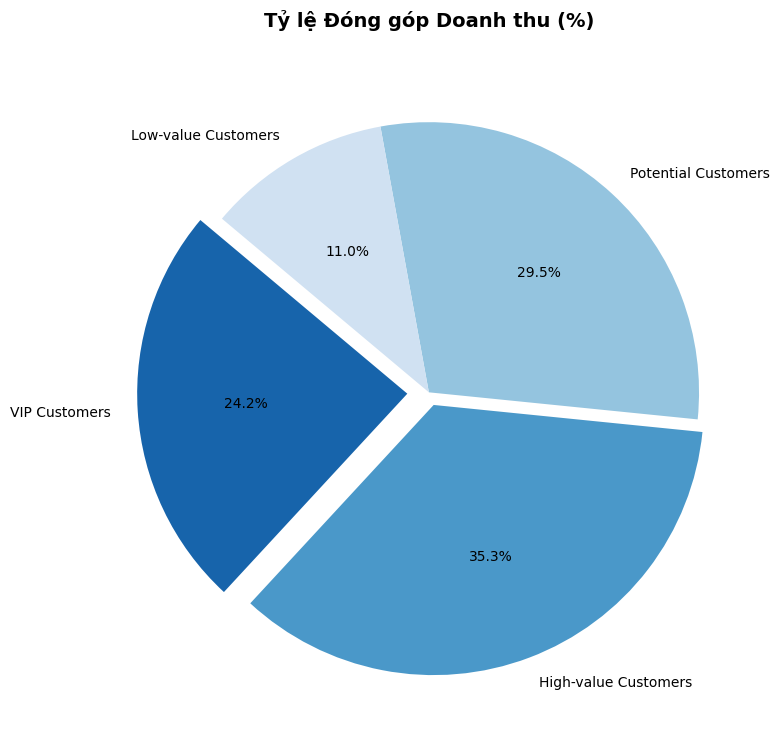

In [21]:
plt.figure(figsize=(8, 8))
plt.pie(
    kpi_ps4['RevenueContribution_%'],
    labels=kpi_ps4['Segment'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette("Blues_r", len(kpi_ps4)),
    explode=[0.08, 0.05, 0, 0]
)
plt.title('Tỷ lệ Đóng góp Doanh thu (%)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


# 21.2 — Biểu đồ 2: So sánh Tần suất mua hàng trung bình giữa các nhóm (Bar Chart)


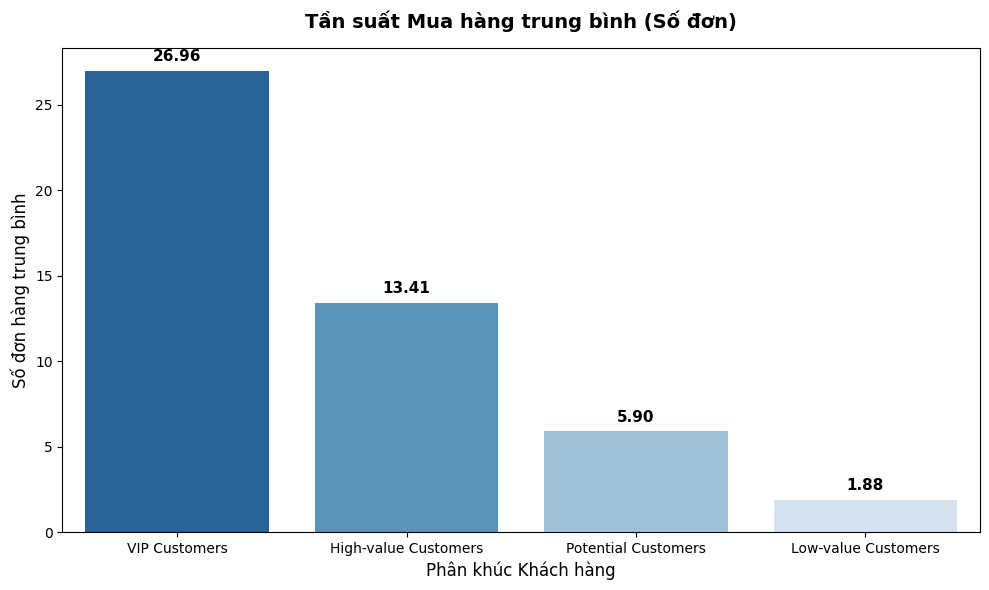

In [22]:
plt.figure(figsize=(10, 6))
ax2 = sns.barplot(
    x='Segment',
    y='AverageFrequency',
    data=kpi_ps4,
    palette='Blues_r',
    hue='Segment',
    legend=False
)
plt.title('Tần suất Mua hàng trung bình (Số đơn)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Phân khúc Khách hàng', fontsize=12)
plt.ylabel('Số đơn hàng trung bình', fontsize=12)

# Hiển thị số liệu chi tiết trên đầu mỗi cột
for p in ax2.patches:
    ax2.annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold', color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()


# 21.3 — Biểu đồ 3: So sánh Khoảng cách giữa các lần mua trung bình giữa các nhóm (Bar Chart)


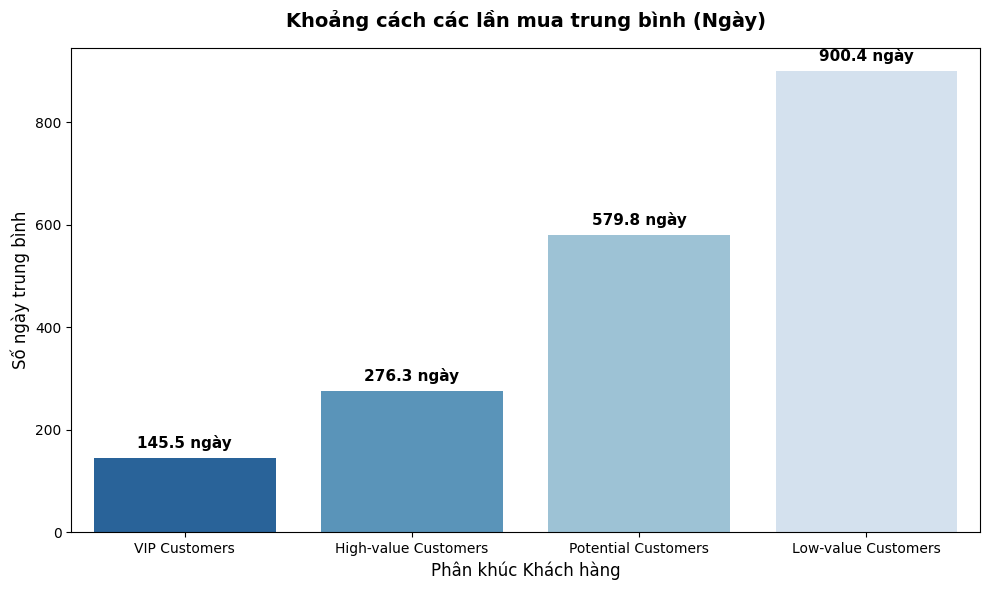

In [23]:
plt.figure(figsize=(10, 6))
ax3 = sns.barplot(
    x='Segment',
    y='AverageInterPurchaseDays',
    data=kpi_ps4,
    palette='Blues_r',
    hue='Segment',
    legend=False
)
plt.title('Khoảng cách các lần mua trung bình (Ngày)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Phân khúc Khách hàng', fontsize=12)
plt.ylabel('Số ngày trung bình', fontsize=12)

# Hiển thị số liệu chi tiết trên đầu mỗi cột
for p in ax3.patches:
    ax3.annotate(
        f"{p.get_height():.1f} ngày",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold', color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

# 22 — Kiểm tra kết quả

In [24]:
print("Duplicate CustomerID:", customer_analysis["customer_id"].duplicated().sum())
print("Null Segment:", customer_analysis["Segment"].isnull().sum())
print("Tần suất mua nhỏ nhất:", customer_analysis["PurchaseFrequency"].min())
print("Tổng CustomerShare (%):", kpi_ps4["CustomerShare_%"].sum())
print("Tổng RevenueContribution (%):", kpi_ps4["RevenueContribution_%"].sum())
print("Tổng doanh thu toàn hệ thống (VNĐ):", f"{total_revenue:,.2f}")
print("Giá trị trung vị doanh thu:", p50)

# ---- Đối chiếu nội bộ: AOV phân khúc gộp lại phải bằng AOV toàn hệ thống
overall_aov = order_data['order_value'].mean()
seg_orders = customer_analysis.groupby('Segment')['PurchaseFrequency'].sum()
seg_rev = customer_analysis.groupby('Segment')['CustomerRevenue'].sum()
print("\nAOV toàn hệ thống (theo đơn):", f"{overall_aov:,.2f}")
print("AOV gộp từ các phân khúc     :", f"{seg_rev.sum() / seg_orders.sum():,.2f}")

# ---- Đối chiếu với PS2 / PS3 (số benchmark lấy từ output của PS2, PS3)
bench = {
    "Số đơn delivered (PS2/PS3)": (len(order_data), 516716, 0),
    "Số khách phân tích (PS1/PS2)": (customer_analysis['customer_id'].nunique(), 85115, 0),
    "Số Repeat Customer (PS2)": (int((customer_analysis['CustomerType'] == 'Repeat Customer').sum()), 62272, 0),
    "Số One-time Buyer (PS2)": (int((customer_analysis['CustomerType'] == 'One-time Buyer').sum()), 22843, 0),
    "Tổng doanh thu (PS3)": (total_revenue, 12518175747.20, 1.0),
    "AOV toàn hệ thống (PS3)": (overall_aov, 24226.41, 0.01),
}
print("\n=== ĐỐI CHIẾU VỚI PS2 / PS3 ===")
for name, (got, expected, tol) in bench.items():
    status = "OK " if abs(got - expected) <= tol else "LỆCH"
    print(f"[{status}] {name}: PS4 = {got:,.2f} | benchmark = {expected:,.2f}")

Duplicate CustomerID: 0
Null Segment: 0
Tần suất mua nhỏ nhất: 1
Tổng CustomerShare (%): 100.0
Tổng RevenueContribution (%): 100.00000000000001
Tổng doanh thu toàn hệ thống (VNĐ): 12,518,175,747.20
Giá trị trung vị doanh thu: 79730.85

AOV toàn hệ thống (theo đơn): 24,226.41
AOV gộp từ các phân khúc     : 24,226.41

=== ĐỐI CHIẾU VỚI PS2 / PS3 ===
[OK ] Số đơn delivered (PS2/PS3): PS4 = 516,716.00 | benchmark = 516,716.00
[OK ] Số khách phân tích (PS1/PS2): PS4 = 85,115.00 | benchmark = 85,115.00
[OK ] Số Repeat Customer (PS2): PS4 = 62,272.00 | benchmark = 62,272.00
[OK ] Số One-time Buyer (PS2): PS4 = 22,843.00 | benchmark = 22,843.00
[OK ] Tổng doanh thu (PS3): PS4 = 12,518,175,747.20 | benchmark = 12,518,175,747.20
[OK ] AOV toàn hệ thống (PS3): PS4 = 24,226.41 | benchmark = 24,226.41


In [25]:
# 23 — Nhận xét kết quả kinh doanh (số liệu được sinh trực tiếp từ kết quả, không gõ tay)
k = kpi_ps4.set_index('Segment')
top20_share = k.loc[['VIP Customers', 'High-value Customers'], 'RevenueContribution_%'].sum()
top20_cust = k.loc[['VIP Customers', 'High-value Customers'], 'CustomerShare_%'].sum()

print(f"- Top {top20_cust:.0f}% khách (VIP + High-value) đóng góp {top20_share:.1f}% tổng doanh thu.")
if top20_share >= 80:
    print("  => Quy luật Pareto 80/20 thể hiện rõ.")
else:
    print(f"  => Chưa đạt mức 80% của quy luật Pareto 80/20 (mức tập trung doanh thu ở mức vừa/cao, không phải cực đoan).")

for seg in ['VIP Customers', 'High-value Customers', 'Potential Customers', 'Low-value Customers']:
    r = k.loc[seg]
    print(f"- {seg}: Repeat {r['RepeatCustomerRate']:.2f}% | tần suất {r['AverageFrequency']:.2f} đơn | "
          f"AOV {r['AverageAOV']:,.0f} VNĐ | chu kỳ mua lại (chỉ Repeat) {r['AverageInterPurchaseDays']:,.0f} ngày")

longest = k['AverageInterPurchaseDays'].idxmax()
lowest_aov = k['AverageAOV'].idxmin()
print(f"\n- Phân khúc có chu kỳ mua lại dài nhất (tính trên khách Repeat): {longest} "
      f"({k.loc[longest, 'AverageInterPurchaseDays']:,.0f} ngày).")
print(f"- Phân khúc có AOV thấp nhất: {lowest_aov} ({k.loc[lowest_aov, 'AverageAOV']:,.0f} VNĐ).")

- Top 20% khách (VIP + High-value) đóng góp 59.5% tổng doanh thu.
  => Chưa đạt mức 80% của quy luật Pareto 80/20 (mức tập trung doanh thu ở mức vừa/cao, không phải cực đoan).
- VIP Customers: Repeat 100.00% | tần suất 26.96 đơn | AOV 26,436 VNĐ | chu kỳ mua lại (chỉ Repeat) 145 ngày
- High-value Customers: Repeat 100.00% | tần suất 13.41 đơn | AOV 25,787 VNĐ | chu kỳ mua lại (chỉ Repeat) 276 ngày
- Potential Customers: Repeat 97.27% | tần suất 5.90 đơn | AOV 24,506 VNĐ | chu kỳ mua lại (chỉ Repeat) 580 ngày
- Low-value Customers: Repeat 47.96% | tần suất 1.88 đơn | AOV 17,206 VNĐ | chu kỳ mua lại (chỉ Repeat) 900 ngày

- Phân khúc có chu kỳ mua lại dài nhất (tính trên khách Repeat): Low-value Customers (900 ngày).
- Phân khúc có AOV thấp nhất: Low-value Customers (17,206 VNĐ).


# 24 — Đề xuất chiến lược chăm sóc và giữ chân khách hàng (Actionable CRM)

> Các con số cụ thể xem bảng `kpi_ps4` và phần nhận xét ở trên; phần dưới chỉ nêu hướng hành động.

- **VIP Customers**: Triển khai các dịch vụ mang tính cá nhân hóa vượt trội (Private CS, VIP Club). Tổ chức sự kiện tri ân đặc quyền hoặc chương trình quà tặng sinh nhật thủ công thiết kế riêng. Thiết lập cổng hỗ trợ giải quyết khiếu nại trong 1 giờ.
- **High-value Customers**: Đẩy mạnh các chiến lược cross-sell/up-sell. Khuyến khích nâng hạng thành viên lên VIP bằng cách tích điểm nhận ưu đãi/voucher mua sắm quy mô lớn.
- **Potential Customers**: Dựa vào `AverageInterPurchaseDays` (tính trên khách Repeat) để xây dựng hệ thống gửi thông điệp cá nhân tự động (Automated SMS/Email/App Push) đúng nhịp mua lại.
- **Low-value Customers**: Nhóm có tỷ lệ One-time cao nhất và chu kỳ mua lại của khách Repeat thuộc nhóm dài nhất (kiểm tra bảng KPI). Dùng chiến dịch đại trà chi phí thấp (Mass email), chương trình combo/đồng giá để tăng AOV, và kích hoạt lại khách sau đơn đầu tiên thay vì đầu tư chăm sóc cá nhân hóa sâu.

In [26]:
# Chạy kiểm tra và in ra chi tiết định nghĩa hệ thống Thước đo, Độ đo và KPI thực tế từ dữ liệu
print("=== KIỂM TRA ĐỊNH NGHĨA HỆ THỐNG CHỈ SỐ ===\n")

# 1. Thước đo (Measures) - Các thuộc tính thô từ bảng nguồn
print("[1] Thước đo (Measures) đã sử dụng:")
print("- Số lượng mua: order_details['quantity'] (Dạng số)")
print("- Đơn giá: order_details['unit_price'] (Dạng số)")
print("- Số tiền giảm giá: order_details['discount_amount'] (Dạng số)")
print("- Ngày đặt hàng: orders_df['order_date'] (Dạng ngày tháng)")
print("- Trạng thái đơn hàng: orders_df['order_status'] (Dạng chuỗi - Lọc 'delivered')\n")

# 2. Độ đo (Metrics) - Các chỉ số được tính toán từ các thước đo
print("[2] Độ đo (Metrics) được tạo thành:")
print(f"- Tổng doanh thu hệ thống sau giảm giá: {total_revenue:,.2f} VNĐ")
print(f"- Số lượng khách hàng giao dịch thành công: {customer_analysis['customer_id'].nunique():,}")
print(f"- Tỷ lệ khách hàng quay lại mua (Repeat Rate) toàn hệ thống: {(customer_analysis['CustomerType'] == 'Repeat Customer').mean() * 100:.2f}%")
print(f"- Giá trị đơn hàng trung bình (AOV) toàn hệ thống: {order_data['order_value'].mean():,.2f} VNĐ\n")

# 3. KPI theo Phân khúc (Segment KPIs)
print("[3] KPI chi tiết theo phân khúc khách hàng (Customer Segment KPIs):")
try:
    display(kpi_ps4)
except NameError:
    print("Bảng kpi_ps4 chưa được định nghĩa hoặc chưa chạy thành công.")

=== KIỂM TRA ĐỊNH NGHĨA HỆ THỐNG CHỈ SỐ ===

[1] Thước đo (Measures) đã sử dụng:
- Số lượng mua: order_details['quantity'] (Dạng số)
- Đơn giá: order_details['unit_price'] (Dạng số)
- Số tiền giảm giá: order_details['discount_amount'] (Dạng số)
- Ngày đặt hàng: orders_df['order_date'] (Dạng ngày tháng)
- Trạng thái đơn hàng: orders_df['order_status'] (Dạng chuỗi - Lọc 'delivered')

[2] Độ đo (Metrics) được tạo thành:
- Tổng doanh thu hệ thống sau giảm giá: 12,518,175,747.20 VNĐ
- Số lượng khách hàng giao dịch thành công: 85,115
- Tỷ lệ khách hàng quay lại mua (Repeat Rate) toàn hệ thống: 73.16%
- Giá trị đơn hàng trung bình (AOV) toàn hệ thống: 24,226.41 VNĐ

[3] KPI chi tiết theo phân khúc khách hàng (Customer Segment KPIs):


,Segment,CustomerCount,CustomerShare_%,SegmentRevenue,RevenueContribution_%,AverageCLV,AverageFrequency,RepeatCustomerRate,AverageAOV,AverageBasketSize,AverageInterPurchaseDays,RepeatCustomerCount
0,VIP Customers,4256,5.00,3033780859.74,24.24,712824.45,26.96,100.00,26436.33,5.16,145.48,4256
1,High-value Customers,12767,15.00,4416158282.03,35.28,345904.15,13.41,100.00,25786.58,5.01,276.33,12767
2,Potential Customers,25535,30.00,3688931551.18,29.47,144465.70,5.90,97.27,24505.64,4.94,579.84,24839
3,Low-value Customers,42557,50.00,1379305054.25,11.02,32410.77,1.88,47.96,17205.61,4.64,900.39,20410
